# 7. Podstawy analizy falkowej

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-07.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 7.1. Wykrywanie załamania sygnału za pomocą ciągłej transformaty falkowej

In [2]:
import numpy as np
import pywt

t = np.linspace(0, 1, 1000, endpoint=False)
s = np.sin(2*np.pi*t) + 1.5*np.abs(t - 0.6)   # załamanie w t = 0,6

W, _ = pywt.cwt(s, [2, 4, 8, 16], "mexh")
for skala, w in zip([2, 4, 8, 16], W):
    w = np.abs(w[100:-100])                    # bez brzegów
    print(f"skala {skala:2d}: maksimum w t = "
          f"{(np.argmax(w) + 100)/1000:.3f}, "
          f"stosunek do mediany {w.max()/np.median(w):6.1f}")

skala  2: maksimum w t = 0.601, stosunek do mediany   18.8
skala  4: maksimum w t = 0.601, stosunek do mediany    9.8
skala  8: maksimum w t = 0.601, stosunek do mediany    5.2
skala 16: maksimum w t = 0.601, stosunek do mediany    2.9


### Kod 7.2. Częstotliwość chwilowa odczytana z grzbietu skalogramu

In [3]:
import numpy as np
import pywt
from scipy.signal import chirp

fs = 400
t = np.arange(0, 4, 1/fs)
s = chirp(t, f0=5, t1=4, f1=50)           # od 5 Hz do 50 Hz

falka = "cmor1.5-1.0"
czest = np.geomspace(3, 80, 120)
skale = pywt.frequency2scale(falka, czest/fs)
W, f = pywt.cwt(s, skale, falka, sampling_period=1/fs)

grzbiet = f[np.argmax(np.abs(W), axis=0)]  # dla każdej chwili
prawdziwa = 5 + 45*t/4
srodek = (t > 0.5) & (t < 3.5)
blad = np.abs(grzbiet - prawdziwa)[srodek]
print(f"średni błąd {blad.mean():.2f} Hz, "
      f"największy {blad.max():.2f} Hz")

średni błąd 0.44 Hz, największy 1.40 Hz


### Kod 7.3. Względna energia poziomów dekompozycji jako opis sygnału

In [4]:
import numpy as np
import pywt

def energia_poziomow(s, falka="db4", poziomy=5):
    """Udział procentowy energii: cA_J, cD_J, ..., cD_1."""
    wsp = pywt.wavedec(s, falka, level=poziomy, mode="periodization")
    e = np.array([np.sum(c**2) for c in wsp])
    return 100*e/e.sum()

rng = np.random.default_rng(0)
t = np.linspace(0, 1, 1024, endpoint=False)
sygnaly = {
    "wolna sinusoida": np.sin(2*np.pi*3*t),
    "szybka sinusoida": np.sin(2*np.pi*200*t),
    "biały szum": rng.normal(size=t.size),
    "fala prostokątna": np.sign(np.sin(2*np.pi*5*t)),
}
print(" "*18, "cA5   cD5   cD4   cD3   cD2   cD1")
for nazwa, s in sygnaly.items():
    print(f"{nazwa:18s}",
          " ".join(f"{e:5.1f}" for e in energia_poziomow(s)))

                   cA5   cD5   cD4   cD3   cD2   cD1
wolna sinusoida    100.0   0.0   0.0   0.0   0.0   0.0
szybka sinusoida     0.0   0.0   0.3   0.1  82.6  17.1
biały szum           2.7   3.5   8.1  10.1  25.8  49.8
fala prostokątna    86.5   6.7   3.5   1.7   0.9   0.7


### Kod 7.4. Usuwanie szumu przez progowanie współczynników falkowych

In [5]:
import numpy as np
import pywt

def odszumianie(z, falka="sym8", poziomy=5, tryb="hard"):
    wsp = pywt.wavedec(z, falka, level=poziomy, mode="periodization")
    sigma = np.median(np.abs(wsp[-1]))/0.6745          # wzór (7.7)
    prog = sigma*np.sqrt(2*np.log(len(z)))             # wzór (7.6)
    wsp = [wsp[0]] + [pywt.threshold(d, prog, tryb) for d in wsp[1:]]
    return pywt.waverec(wsp, falka, mode="periodization"), sigma

def snr(wzorzec, x):
    """Stosunek sygnału do szumu w decybelach."""
    return 10*np.log10(np.sum(wzorzec**2)/np.sum((wzorzec - x)**2))

rng = np.random.default_rng(42)
N = 2048
x = np.linspace(0, 1, N, endpoint=False)
czysty = (np.sin(2*np.pi*3*x) + np.where(x > 0.3, 1.0, 0)
          - np.where(x > 0.72, 1.5, 0)
          + 0.5*np.exp(-((x - 0.5)/0.01)**2))
zaszumiony = czysty + 0.2*rng.normal(size=N)

print(f"przed: {snr(czysty, zaszumiony):.1f} dB")
for tryb in ("hard", "soft"):
    wynik, sigma = odszumianie(zaszumiony, tryb=tryb)
    print(f"progowanie {tryb}: {snr(czysty, wynik):.1f} dB, "
          f"oszacowane sigma = {sigma:.3f}")

# dla porównania: średnia ruchoma z 17 próbek
srednia = np.convolve(zaszumiony, np.ones(17)/17, "same")
print(f"średnia ruchoma: {snr(czysty, srednia):.1f} dB")

przed: 14.2 dB
progowanie hard: 24.9 dB, oszacowane sigma = 0.192
progowanie soft: 23.5 dB, oszacowane sigma = 0.192
średnia ruchoma: 23.3 dB


### Kod 7.5. Przybliżenie sygnału niewielką liczbą współczynników: falki i baza Fouriera

In [6]:
import numpy as np
import pywt

N = 2048
x = np.linspace(0, 1, N, endpoint=False)
s = (np.sin(2*np.pi*3*x) + np.where(x > 0.3, 1.0, 0)
     - np.where(x > 0.72, 1.5, 0)
     + 0.5*np.exp(-((x - 0.5)/0.01)**2))

wsp = pywt.wavedec(s, "sym8", mode="periodization")
tab, uklad = pywt.coeffs_to_array(wsp)       # wszystkie w jednej tablicy
F = np.fft.fft(s)/np.sqrt(N)                 # baza ortonormalna

def zostaw_najwieksze(c, K):
    prog = np.sort(np.abs(c))[-K]
    return np.where(np.abs(c) >= prog, c, 0)

for procent in (2, 5, 10):
    K = N*procent//100
    w = pywt.array_to_coeffs(zostaw_najwieksze(tab, K), uklad,
                             output_format="wavedec")
    s_falki = pywt.waverec(w, "sym8", mode="periodization")
    F_K = zostaw_najwieksze(F, K)*np.sqrt(N)
    s_fourier = np.fft.ifft(F_K).real
    blad = lambda y: 100*np.linalg.norm(y - s)/np.linalg.norm(s)
    print(f"{procent:2d}% ({K:3d} współczynników): falki "
          f"{blad(s_falki):6.3f}%, Fourier {blad(s_fourier):5.2f}%")

 2% ( 40 współczynników): falki  4.246%, Fourier  8.50%
 5% (102 współczynników): falki  0.518%, Fourier  5.34%
10% (204 współczynników): falki  0.003%, Fourier  3.69%


## Ćwiczenia i rozwiązania

### Ćwiczenie 7.1
Zmień w kodzie 7.1 załamanie na skok drugiej pochodnej: dodaj do sinusoidy składnik równy 20(t − 0,6)² dla t > 0,6 i zeru poza tym. Czy falka „meksykański kapelusz” nadal wykrywa osobliwość? Sprawdź falkę `gaus3`.

### Rozwiązanie 7.1

mexh maksimum w t = 0.751 stosunek do mediany: 2.1
gaus3 maksimum w t = 0.6 stosunek do mediany: 23.0


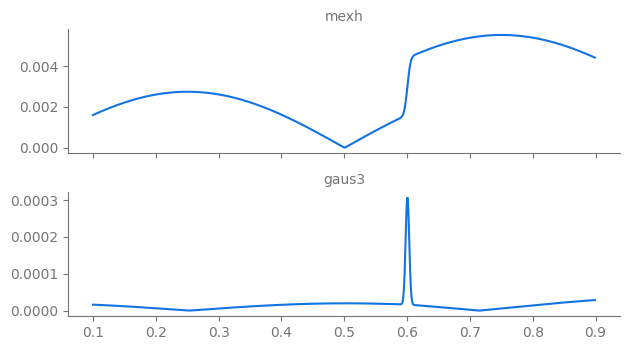

In [7]:
t = np.linspace(0, 1, 1000, endpoint=False)
s = np.sin(2*np.pi*t) + np.where(t > 0.6, 20*(t - 0.6)**2, 0)
fig, axs = plt.subplots(2, 1, figsize=(6.4, 3.6), sharex=True)
for ax, falka in zip(axs, ("mexh", "gaus3")):
    W, _ = pywt.cwt(s, [4], falka)
    w = np.abs(W[0][100:-100])
    print(falka, "maksimum w t =", (np.argmax(w) + 100)/1000,
          "stosunek do mediany:", round(w.max()/np.median(w), 1))
    ax.plot(t[100:-100], w, color=NIEBIESKI); ax.set_title(falka)
plt.tight_layout(); plt.show()
# „Meksykański kapelusz” (druga pochodna) pokazuje w tym miejscu tylko schodek;
# falka gaus3 (trzecia pochodna) daje wyraźny szczyt. Falka musi mieć więcej
# znikających momentów, niż wynosi rząd pochodnej, która jest jeszcze ciągła.

### Ćwiczenie 7.2
Oszacuj wykładnik Lipschitza skoku jednostkowego z nachylenia wykresu log |W| względem log a.

### Rozwiązanie 7.2

In [8]:
s = (np.arange(4096) >= 2048).astype(float)
skale = np.array([2, 4, 8, 16, 32, 64])
W, _ = pywt.cwt(s, skale, "gaus1")
maks = np.abs(W[:, 1024:3072]).max(axis=1)
nachylenie = np.polyfit(np.log(skale), np.log(maks), 1)[0]
print("nachylenie:", round(nachylenie, 3),
      "→ wykładnik Lipschitza:", round(nachylenie - 0.5, 3))

nachylenie: 0.5 → wykładnik Lipschitza: 0.0


### Ćwiczenie 7.3
Wyznacz grzbiet skalogramu sygnału o częstotliwości zmieniającej się sinusoidalnie wokół 30 Hz.

### Rozwiązanie 7.3

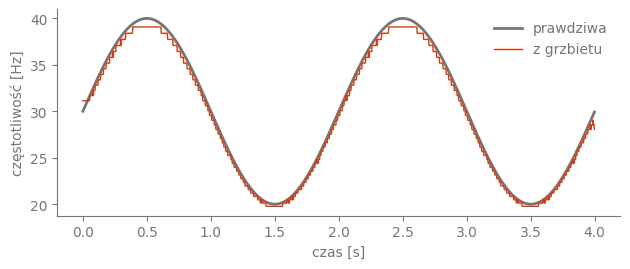

średni błąd: 0.48 Hz


In [9]:
fs = 400
t = np.arange(0, 4, 1/fs)
f_chw = 30 + 10*np.sin(2*np.pi*0.5*t)
s = np.cos(2*np.pi*np.cumsum(f_chw)/fs)
falka = "cmor1.5-1.0"
czest = np.geomspace(10, 80, 120)
W, f = pywt.cwt(s, pywt.frequency2scale(falka, czest/fs), falka,
                sampling_period=1/fs)
grzbiet = f[np.argmax(np.abs(W), axis=0)]
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.plot(t, f_chw, color=SZARY, lw=2, label="prawdziwa")
ax.plot(t, grzbiet, color=RDZAWY, lw=1, label="z grzbietu")
ax.set_xlabel("czas [s]"); ax.set_ylabel("częstotliwość [Hz]")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("średni błąd:", round(np.mean(np.abs(grzbiet - f_chw)[200:-200]), 2), "Hz")

### Ćwiczenie 7.4
Wyznacz rozkład energii między poziomy dla sumy wolnej sinusoidy i białego szumu przy trzech poziomach szumu. Jak zmieniają się udziały?

### Rozwiązanie 7.4

In [10]:
rng = np.random.default_rng(1)
t = np.linspace(0, 1, 1024, endpoint=False)
for sigma in (0.1, 0.5, 2.0):
    s = np.sin(2*np.pi*3*t) + sigma*rng.normal(size=t.size)
    wsp = pywt.wavedec(s, "db4", level=5, mode="periodization")
    e = np.array([np.sum(c**2) for c in wsp]); e = 100*e/e.sum()
    print(f"sigma = {sigma}:", " ".join(f"{u:5.1f}" for u in e))

sigma = 0.1:  98.2   0.0   0.1   0.2   0.5   1.0
sigma = 0.5:  65.7   1.5   1.8   4.8   8.6  17.6
sigma = 2.0:  12.8   3.1   4.8  11.2  22.5  45.7


### Ćwiczenie 7.5
Zbadaj, jak wynik odszumiania w kodzie 7.4 zależy od wyboru falki (`haar`, `db4`, `sym8`, `coif3`) i od liczby poziomów.

### Rozwiązanie 7.5

In [11]:
def odszumianie(z, falka="sym8", poziomy=5, tryb="hard", mnoznik=1.0):
    wsp = pywt.wavedec(z, falka, level=poziomy, mode="periodization")
    sigma = np.median(np.abs(wsp[-1]))/0.6745
    prog = mnoznik*sigma*np.sqrt(2*np.log(len(z)))
    wsp = [wsp[0]] + [pywt.threshold(d, prog, tryb) for d in wsp[1:]]
    return pywt.waverec(wsp, falka, mode="periodization")

def snr(wzorzec, x):
    return 10*np.log10(np.sum(wzorzec**2)/np.sum((wzorzec - x)**2))

rng = np.random.default_rng(42)
N = 2048
x = np.linspace(0, 1, N, endpoint=False)
czysty = (np.sin(2*np.pi*3*x) + np.where(x > 0.3, 1.0, 0)
          - np.where(x > 0.72, 1.5, 0) + 0.5*np.exp(-((x - 0.5)/0.01)**2))
zaszumiony = czysty + 0.2*rng.normal(size=N)
print("poziomy:      3     4     5     6")
for falka in ("haar", "db4", "sym8", "coif3"):
    print(f"{falka:6s}", " ".join(
        f"{snr(czysty, odszumianie(zaszumiony, falka, p)):5.1f}"
        for p in (3, 4, 5, 6)))

poziomy:      3     4     5     6
haar    22.1  23.6  22.6  21.8
db4     22.3  23.5  24.0  24.2
sym8    22.0  24.1  24.9  23.9
coif3   22.3  23.9  24.7  24.2


### Ćwiczenie 7.6
Pomnóż próg uniwersalny przez współczynnik od 0,2 do 1,5 i wyznacz stosunek sygnału do szumu po progowaniu twardym. Dla jakiego współczynnika jest on największy?

### Rozwiązanie 7.6

najlepszy mnożnik: 0.95 SNR: 25.0 dB


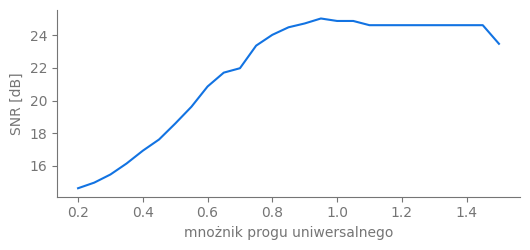

In [12]:
mnozniki = np.linspace(0.2, 1.5, 27)
wyniki = [snr(czysty, odszumianie(zaszumiony, mnoznik=m)) for m in mnozniki]
print("najlepszy mnożnik:", round(mnozniki[int(np.argmax(wyniki))], 2),
      "SNR:", round(max(wyniki), 1), "dB")
fig, ax = plt.subplots(figsize=(5.4, 2.6))
ax.plot(mnozniki, wyniki, color=NIEBIESKI)
ax.set_xlabel("mnożnik progu uniwersalnego"); ax.set_ylabel("SNR [dB]")
plt.tight_layout(); plt.show()

### Ćwiczenie 7.7
Powtórz obliczenia z kodu 7.5 dla sygnału gładkiego, na przykład sumy trzech sinusoid. Która baza jest teraz lepsza i dlaczego?

### Rozwiązanie 7.7

In [13]:
s = np.sin(2*np.pi*3*x) + 0.5*np.sin(2*np.pi*17*x) + 0.2*np.cos(2*np.pi*40*x)
tab, uklad = pywt.coeffs_to_array(pywt.wavedec(s, "sym8", mode="periodization"))
F = np.fft.fft(s)/np.sqrt(N)
def blad(c, K):
    e = np.sort(np.abs(c)**2)[::-1]
    return 100*np.sqrt(max(e[K:].sum(), 0)/e.sum())
for K in (6, 20, 40, 100):
    print(f"K = {K:3d}: falki {blad(tab, K):7.3f}%, Fourier {blad(F, K):7.3f}%")

K =   6: falki  69.765%, Fourier   0.000%
K =  20: falki  41.482%, Fourier   0.000%
K =  40: falki  24.764%, Fourier   0.000%
K = 100: falki   5.491%, Fourier   0.000%


### Ćwiczenie 7.8
Narysuj uporządkowane malejąco moduły współczynników falkowych i fourierowskich sygnału z kodu 7.5 w skali logarytmicznej.

### Rozwiązanie 7.8

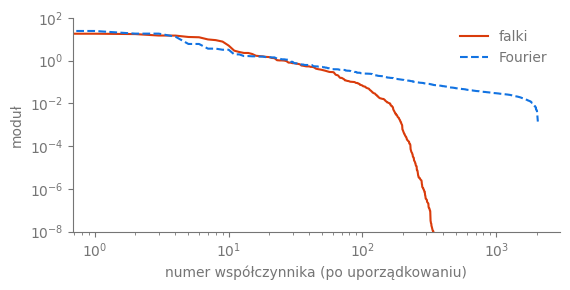

In [14]:
tab, _ = pywt.coeffs_to_array(pywt.wavedec(czysty, "sym8", mode="periodization"))
F = np.fft.fft(czysty)/np.sqrt(N)
fig, ax = plt.subplots(figsize=(5.8, 3.0))
ax.loglog(np.sort(np.abs(tab))[::-1] + 1e-16, color=RDZAWY, label="falki")
ax.loglog(np.sort(np.abs(F))[::-1] + 1e-16, color=NIEBIESKI, ls="--",
          label="Fourier")
ax.set_ylim(1e-8, 100); ax.set_xlabel("numer współczynnika (po uporządkowaniu)")
ax.set_ylabel("moduł"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()